Analisis exploratorio de datos

Librerias

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

Carga de informacion

In [2]:
df = pd.read_csv("listings_clean.csv", parse_dates=["price_quote_checkin_date"])
print(f"Registros: {len(df):,}  |  Variables: {df.shape[1]}  |  Datos faltantes: {int(df.isna().sum().sum())}")
df.head(3)

Registros: 33,590  |  Variables: 64  |  Datos faltantes: 0


,id,price,log_price,island,neighbourhood,latitude,longitude,room_type,property_group,accommodates,...,am_dishwasher,am_tv,am_bbq,am_beach_waterfront,am_ocean_view,am_gym,am_elevator,am_self_checkin,am_workspace,am_patio_balcony
0,784020,848.33,6.743270,Maui,Lahaina,20.995184,-156.665009,Entire home/apt,House,8,...,1,1,1,1,0,0,0,1,1,1
1,461638,101.86,4.623599,Hawaii,South Hilo,19.721000,-155.084950,Private room,House,1,...,0,0,0,0,0,0,0,0,0,1
2,479121,265.00,5.579730,Hawaii,Puna,19.400310,-154.920430,Entire home/apt,House,6,...,0,1,1,1,1,0,0,0,0,1


creacion de caracteristicas de comparacion para el analisis
price_per_person: precio/capacidad
host_size:tamaño del operador
Rating:calificacion en bandas

In [3]:
df["price_per_person"] = df["price"] / df["accommodates"]
df["host_size"] = pd.cut(df["calculated_host_listings_count"], [0, 1, 5,50, np.inf],
labels=["1 anuncio", "2–5", "6–50", "más de 50"])
df["rating_band"] = pd.cut(df["review_scores_rating"], [0, 4.5, 4.7, 4.8, 4.9, 5.0],
labels=["< 4.5", "4.5–4.7", "4.7–4.8", "4.8–4.9", "4.9–5.0"], include_lowest=True)
amenidades = [c for c in df.columns if c.startswith("am_")]

Estadisticas descriptivas

In [5]:
numericas = ["price", "price_per_person", "accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights",
             "availability_365", "estimated_occupancy_l365d", "host_years", "calculated_host_listings_count",
             "number_of_reviews", "reviews_per_month", "review_scores_rating", "review_scores_value", "n_amenities"]
desc = df[numericas].describe(percentiles=[.25, .5, .75]).T
desc["asimetría"] = df[numericas].skew()
desc["curtosis"] = df[numericas].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
price,33590.0,495.15,377.42,67.72,257.12,375.50,594.00,2409.80,2.13,5.33
price_per_person,33590.0,106.95,64.88,7.16,64.58,91.00,130.67,1615.00,2.79,21.93
accommodates,33590.0,4.79,2.32,1.00,4.00,4.00,6.00,16.00,1.49,3.99
bedrooms,33590.0,1.54,1.02,0.00,1.00,1.00,2.00,5.00,0.79,0.90
beds,33590.0,2.61,1.40,1.00,2.00,2.00,3.00,8.00,1.26,2.12
bathrooms,33590.0,1.60,0.77,0.00,1.00,1.00,2.00,4.50,1.28,1.74
minimum_nights,33590.0,5.80,19.22,1.00,1.00,2.00,3.00,365.00,9.26,107.04
availability_365,33590.0,233.74,97.17,0.00,175.00,256.00,309.00,365.00,-0.72,-0.41
estimated_occupancy_l365d,33590.0,55.46,73.75,0.00,0.00,18.00,90.00,255.00,1.37,0.79
host_years,33590.0,6.91,3.86,0.00,3.92,6.92,10.17,15.67,0.03,-0.97


composicion

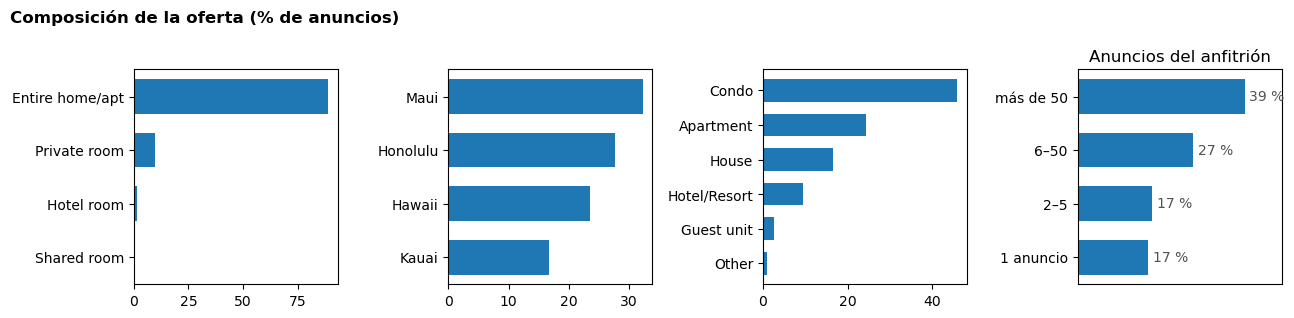

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (c, titulo) in zip(axes, [("room_type", "Tipo de alojamiento"), ("island", "Isla"),("property_group", "Tipo de edificación"), ("host_size", "Anuncios del anfitrión")]):
    vc = (df[c].value_counts(normalize=True) * 100).sort_values()
    ax.barh(vc.index.astype(str), vc.values, height=0.65)
for y, v in enumerate(vc.values):
    ax.text(v + 1, y, f"{v:.0f} %", va="center", color="#52514e")
ax.set_title(titulo); ax.set_xlim(0, vc.max() * 1.22); ax.grid(False); ax.set_xticks([])
plt.suptitle("Composición de la oferta (% de anuncios)", x=0.01 ,ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

el 89% de los alojaminetos son completos, casio la mitad son condominios luegos aptos y casas.

el 39% pertenece a administradores de propiedades vs 17% a personas con un solo anuncio


Variable objetivo precio por noche

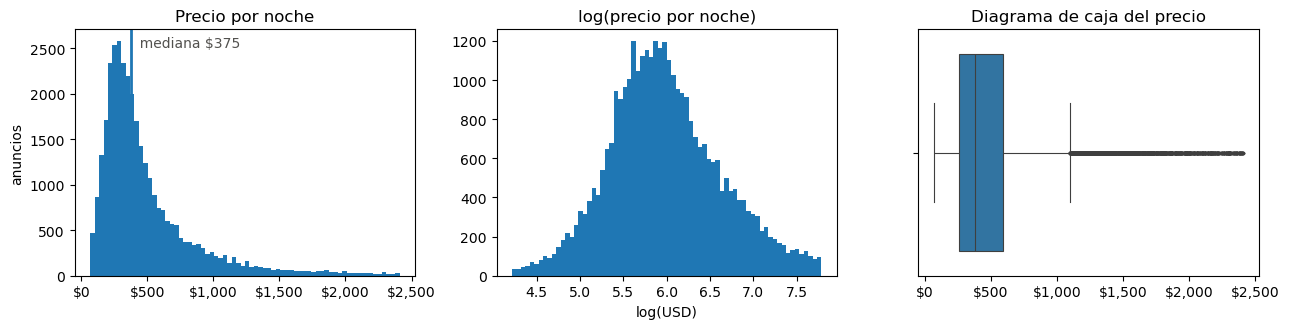

Media $495 | Mediana $375 | Rango intercuartílico $257–$594 | Asimetría precio 2.13 vs. log(precio) 0.28


In [20]:
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(df["price"], bins=70)
axes[0].axvline(df["price"].median(), lw=2)
axes[0].text(df["price"].median(), axes[0].get_ylim()[1] * 0.93, f"  mediana ${df['price'].median():,.0f}", color="#52514e")
axes[0].set_title("Precio por noche"); axes[0].xaxis.set_major_formatter(usd); axes[0].set_ylabel("anuncios")
axes[1].hist(df["log_price"], bins=70)
axes[1].set_title("log(precio por noche)"); axes[1].set_xlabel("log(USD)")
sns.boxplot(x=df["price"], ax=axes[2], fliersize=1.5, linewidth=0.8)
axes[2].set_title("Diagrama de caja del precio"); axes[2].xaxis.set_major_formatter(usd); axes[2].set_xlabel("")
plt.tight_layout()
plt.show()
print(f"Media ${df['price'].mean():,.0f} | Mediana ${df['price'].median():,.0f} | "
      f"Rango intercuartílico ${df['price'].quantile(.25):,.0f}–${df['price'].quantile(.75):,.0f} | "
      f"Asimetría precio {df['price'].skew():.2f} vs. log(precio) {df['log_price'].skew():.2f}")


el precio mediano por noche es de 375 USD por noche y la mitad de los anuncios esta en 257 - 594 la media 495 usd  

tien cola pesada a la derecha aplicamos logaritmo  y ya parece una normal

por lo que ahora nuetra variable es log (precios)


precio y ubicacion

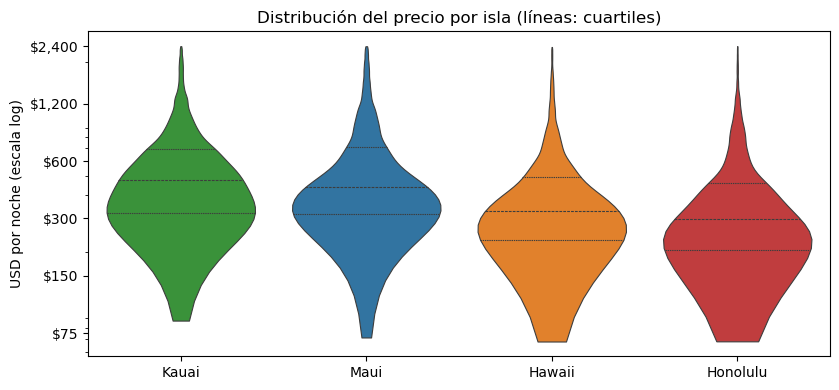

,count,25%,50%,75%
island,,,,
Kauai,5586.0,320.0,475.0,693.0
Maui,10830.0,315.0,437.0,709.0
Hawaii,7907.0,230.0,328.0,493.0
Honolulu,9267.0,204.0,297.0,463.0


In [ ]:
orden_islas = df.groupby("island")["price"].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 4))
sns.violinplot(data=df, x="island", y="price", hue="island", order=orden_islas,inner="quartile", cut=0, linewidth=0.8, legend=False, ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set_yticks([75, 150, 300, 600, 1200, 2400])
ax.set_xlabel(""); ax.set_ylabel("USD por noche (escala log)")
ax.set_title("Distribución del precio por isla (líneas: cuartiles)")
plt.tight_layout()
plt.show()
df.groupby("island")["price"].describe()[["count", "25%", "50%", "75%"]].loc[orden_islas].round(0)

precio por zona

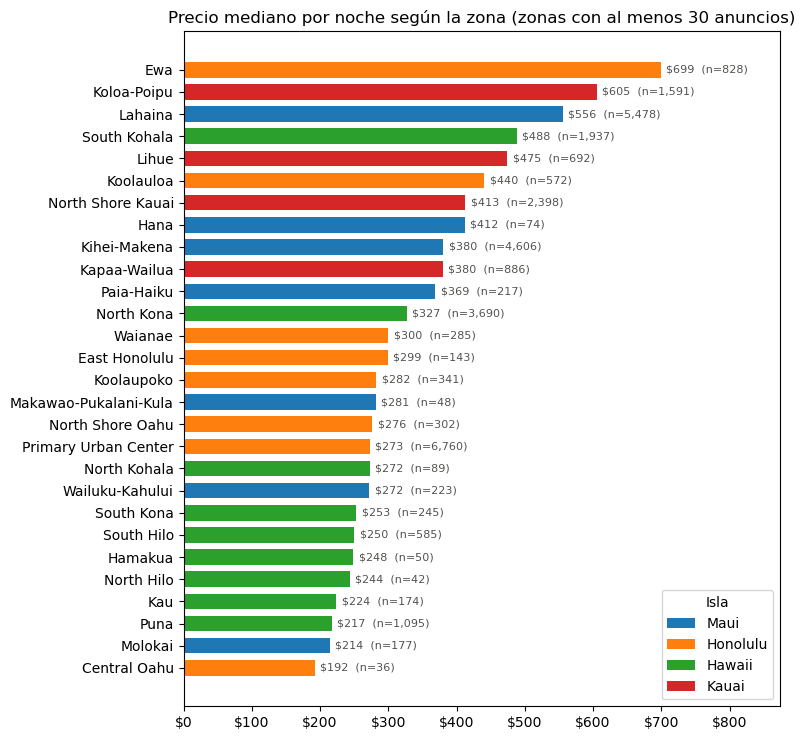

In [35]:
from matplotlib.patches import Patch

colores = {
    "Maui": "#1f77b4",
    "Honolulu": "#ff7f0e",
    "Hawaii": "#2ca02c",
    "Kauai": "#d62728",
}

zonas = df.groupby(["neighbourhood", "island"])["price"].agg(mediana="median", anuncios="size").reset_index()
zonas = zonas[zonas["anuncios"] >= 30].sort_values("mediana")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(zonas["neighbourhood"], zonas["mediana"],color=zonas["island"].map(colores), height=0.7)
for y, (v, n) in enumerate(zip(zonas["mediana"], zonas["anuncios"])):
    ax.text(v + 8, y, f"${v:,.0f}  (n={n:,})", va="center", color="#52514e", fontsize=8)
ax.xaxis.set_major_formatter(usd); ax.set_xlim(0, zonas["mediana"].max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Precio mediano por noche según la zona (zonas con al menos 30 anuncios)")
ax.legend(handles=[Patch(facecolor=c, label=isla) for isla, c in colores.items()], title="Isla", loc="lower right")
plt.tight_layout()
plt.show()

NOTA SUPER IMPORTANTE 

Mapra de calor de alojamientos y su distribucion 

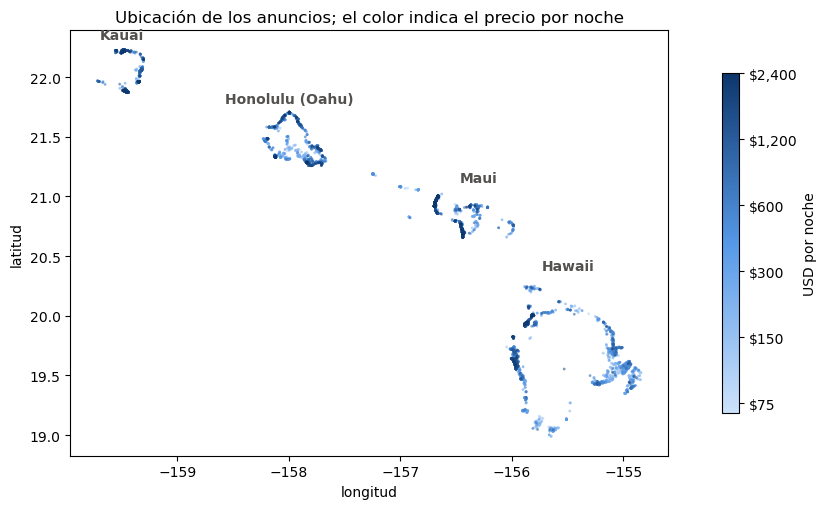

In [37]:
fig, ax = plt.subplots(figsize=(11, 5.2))
m = df.sort_values("price")
sc = ax.scatter(m["longitude"], m["latitude"], c=m["log_price"], cmap=LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#5598e7", "#0d366b"]), s=4, alpha=0.6, linewidths=0)
cb = plt.colorbar(sc, ax=ax, shrink=0.8, ticks=np.log([75, 150, 300, 600, 1200, 2400]))
cb.solids.set_alpha(1)
cb.ax.set_yticklabels(["$75", "$150", "$300", "$600", "$1,200", "$2,400"]); cb.set_label("USD por noche")
for isla, (x, y) in {"Kauai": (-159.5, 22.32), "Honolulu (Oahu)": (-158.0, 21.78), "Maui": (-156.3, 21.12), "Hawaii": (-155.5, 20.38)}.items():
    ax.text(x, y, isla, ha="center", color="#52514e", fontweight="bold")
ax.set_aspect(1 / np.cos(np.radians(20.9))); ax.grid(False)
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title("Ubicación de los anuncios; el color indica el precio por noche")
plt.tight_layout()
plt.show()

Vemos una clara tendencia que los bordes de la isla son los mas apetecidos

Precios y caracteristicas por inmueble

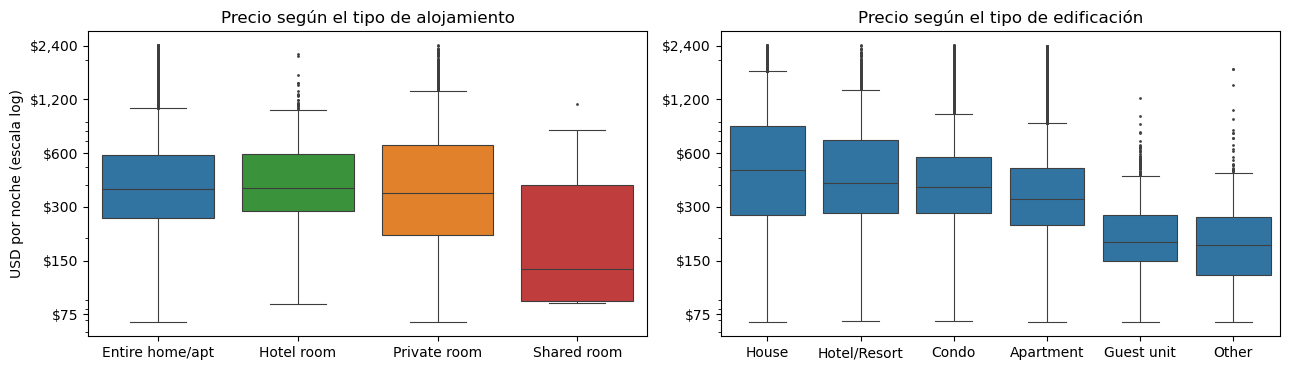

,count,25%,50%,75%
room_type,,,,
Entire home/apt,29855.0,260.0,377.0,588.0
Hotel room,492.0,285.0,381.0,597.0
Private room,3225.0,209.0,357.0,664.0
Shared room,18.0,89.0,136.0,396.0


In [41]:
colorestipo = {
    "Entire home/apt": "#1f77b4",
    "Private room": "#ff7f0e",
    "Hotel room": "#2ca02c",
    "Shared room": "#d62728",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
orden_tipo = ["Entire home/apt", "Hotel room", "Private room", "Shared room"]
sns.boxplot(data=df, x="room_type", y="price", hue="room_type", order=orden_tipo, palette=colorestipo,
            fliersize=1, linewidth=0.8, legend=False, ax=axes[0])
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(usd); axes[0].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[0].set_xlabel(""); axes[0].set_ylabel("USD por noche (escala log)"); axes[0].set_title("Precio según el tipo de alojamiento")
orden_prop = df.groupby("property_group")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="property_group", y="price", order=orden_prop, fliersize=1, linewidth=0.8, ax=axes[1])
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(usd); axes[1].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[1].set_xlabel(""); axes[1].set_ylabel(""); axes[1].set_title("Precio según el tipo de edificación")
plt.tight_layout()
plt.show()
df.groupby("room_type")["price"].describe()[["count", "25%", "50%", "75%"]].loc[orden_tipo].round(0)

Precios y caracterisircas de los inmubeles

In [42]:
cruce = df[df["room_type"].isin(["Entire home/apt", "Private room"])].pivot_table(
    index="property_group", columns="room_type", values="price", aggfunc=["median", "size"]).round(0)
cruce.columns = [f"{'mediana USD' if a == 'median' else 'anuncios'} · {b}" for a, b in cruce.columns]
cruce

,mediana USD · Entire home/apt,mediana USD · Private room,anuncios · Entire home/apt,anuncios · Private room
property_group,,,,
Apartment,332.0,217.0,8099,83
Condo,386.0,269.0,15352,87
Guest unit,195.0,184.0,739,99
Hotel/Resort,278.0,426.0,213,2494
House,512.0,149.0,5193,383
Other,193.0,171.0,259,79


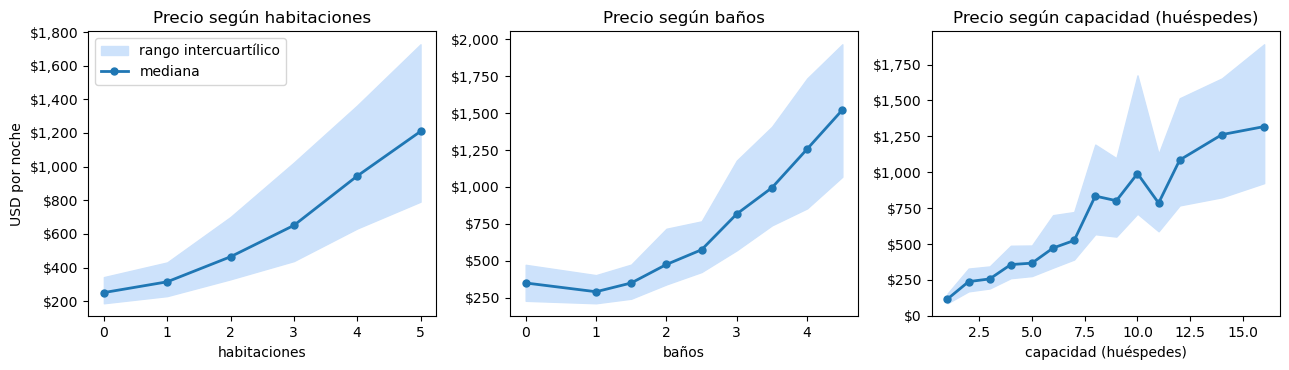

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c, titulo in zip(axes, ["bedrooms", "bathrooms", "accommodates"], ["habitaciones", "baños", "capacidad (huéspedes)"]):
    g = df.groupby(c)["price"].agg(["median", "size", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
    g.columns = ["mediana", "n", "q1", "q3"]
    g = g[g["n"] >= 50]
    ax.fill_between(g.index, g["q1"], g["q3"], color="#cde2fb", label="rango intercuartílico")
    ax.plot(g.index, g["mediana"], lw=2, marker="o", ms=5, label="mediana")
    ax.yaxis.set_major_formatter(usd); ax.set_xlabel(titulo); ax.set_title(f"Precio según {titulo}")
axes[0].set_ylabel("USD por noche"); axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

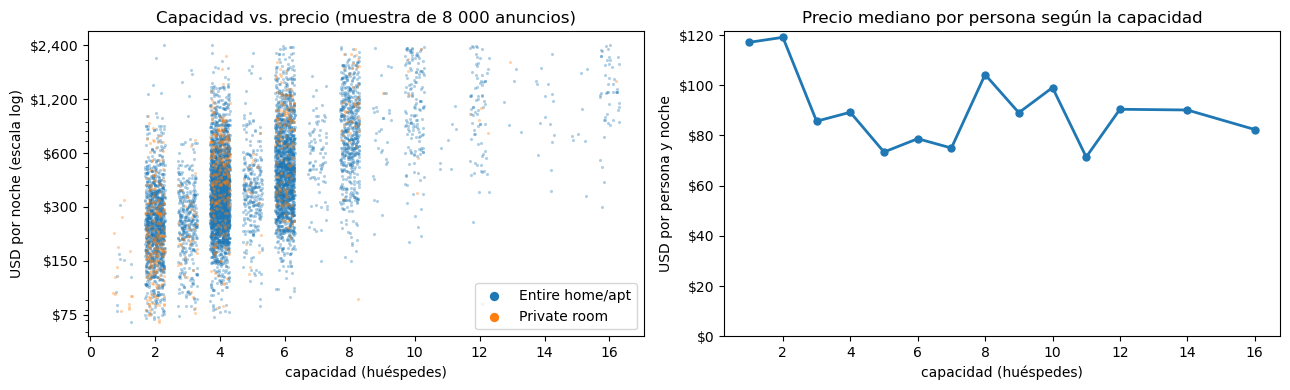

In [47]:
rng = np.random.default_rng(0)
muestra = df.sample(8000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for tipo in ["Entire home/apt", "Private room"]:
    s = muestra[muestra["room_type"] == tipo]
    axes[0].scatter(s["accommodates"] + rng.uniform(-0.3, 0.3, len(s)), s["price"], s=5, alpha=0.35, color=colorestipo[tipo], linewidths=0, label=tipo)
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(usd); axes[0].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[0].set_xlabel("capacidad (huéspedes)"); axes[0].set_ylabel("USD por noche (escala log)")
axes[0].set_title("Capacidad vs. precio (muestra de 8 000 anuncios)")
leg = axes[0].legend(markerscale=3, loc="lower right")
for h in leg.legend_handles:
    h.set_alpha(1)

pp = df.groupby("accommodates")["price_per_person"].median()
pp = pp[df["accommodates"].value_counts().reindex(pp.index) >= 50]
axes[1].plot(pp.index, pp.values, lw=2, marker="o", ms=5)
axes[1].yaxis.set_major_formatter(usd); axes[1].set_ylim(0)
axes[1].set_xlabel("capacidad (huéspedes)"); axes[1].set_ylabel("USD por persona y noche")
axes[1].set_title("Precio mediano por persona según la capacidad")
plt.tight_layout()
plt.show()

observamos que el tamaño es el factor que mas mueve el precio,la mediana pasa de 251 estudio a 315 1 habitacion 464 2 habitaciones 650 3 habitaciones y mas de 1200 por 5 habitaciones


precio por persona baja con tamaño 

las casa y hoteles/resorts son los mas caros

Analisis de amenidades por vivienda

In [51]:
controles_num = ["accommodates", "bedrooms", "beds", "bathrooms", "bath_shared", "long_stay", "quote_nights", "quote_lead_days"]
X = pd.concat([df[controles_num], df[amenidades],
               pd.get_dummies(df[["room_type", "property_group", "neighbourhood"]], drop_first=True, dtype=int),
               pd.get_dummies(df["quote_checkin_month"], prefix="mes", drop_first=True, dtype=int)], axis=1)
reg = LinearRegression().fit(X, df["log_price"])
print(f"R² de la regresión de control: {reg.score(X, df['log_price']):.2f}")
coef = pd.Series(reg.coef_, index=X.columns)

tabla_am = pd.DataFrame({
    "% de anuncios": df[amenidades].mean() * 100,
    "mediana con": [df.loc[df[a] == 1, "price"].median() for a in amenidades],
    "mediana sin": [df.loc[df[a] == 0, "price"].median() for a in amenidades],
}, index=amenidades)
tabla_am["dif. bruta %"] = (tabla_am["mediana con"] / tabla_am["mediana sin"] - 1) * 100
tabla_am["dif. ajustada %"] = (np.exp(coef[amenidades]) - 1) * 100
tabla_am.index = tabla_am.index.str.replace("am_", "")
tabla_am = tabla_am.sort_values("dif. ajustada %")
tabla_am.round(1)

R² de la regresión de control: 0.62


,% de anuncios,mediana con,mediana sin,dif. bruta %,dif. ajustada %
self_checkin,71.1,371.7,389.0,-4.4,-6.7
washer,82.0,394.0,308.8,27.6,-5.1
bbq,68.9,409.0,307.3,33.1,-3.8
free_parking,76.2,380.7,361.0,5.5,-3.3
elevator,36.7,373.0,377.5,-1.2,-0.6
patio_balcony,70.1,399.8,321.0,24.5,0.1
workspace,54.8,402.0,346.7,16.0,1.7
hot_tub,48.3,426.3,333.2,27.9,4.0
tv,96.1,383.0,207.0,85.0,4.3
pool,79.3,400.0,278.3,43.7,4.4


diagrama de tornado

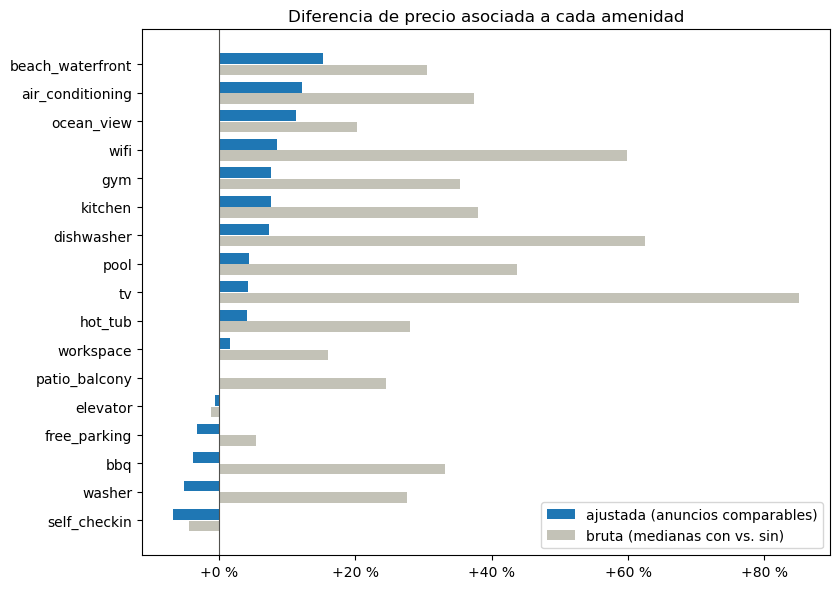

In [53]:
fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(tabla_am))
ax.barh(y + 0.2, tabla_am["dif. ajustada %"], height=0.38, label="ajustada (anuncios comparables)")
ax.barh(y - 0.2, tabla_am["dif. bruta %"], height=0.38, color="#c3c2b7", label="bruta (medianas con vs. sin)")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(tabla_am.index)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f} %"))
ax.grid(axis="y", visible=False)
ax.set_title("Diferencia de precio asociada a cada amenidad")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Buscar realacion entre amenidades y precio y calificacion

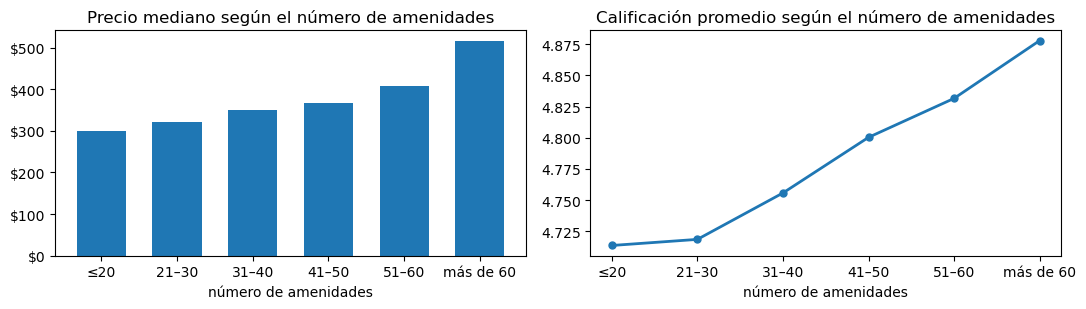

In [56]:
df["amen_bin"] = pd.cut(df["n_amenities"], [-1, 20, 30, 40, 50, 60, 200], labels=["≤20", "21–30", "31–40", "41–50", "51–60", "más de 60"])
g = df.groupby("amen_bin", observed=True).agg(precio=("price", "median"), calificacion=("review_scores_rating", "mean"), n=("price", "size"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(g.index.astype(str), g["precio"], width=0.65)
axes[0].yaxis.set_major_formatter(usd); axes[0].set_title("Precio mediano según el número de amenidades"); axes[0].grid(axis="x", visible=False)
con_res = df[df["has_reviews"] == 1].groupby("amen_bin", observed=True)["review_scores_rating"].mean()
axes[1].plot(con_res.index.astype(str), con_res.values, lw=2, marker="o", ms=5)
axes[1].set_title("Calificación promedio según el número de amenidades"); axes[1].set_xlabel("número de amenidades")
axes[0].set_xlabel("número de amenidades")
plt.tight_layout()
plt.show()

las diferecnias brutas exageran el efecto de casi todas las amenidades, porque viene acompañadas de inmuebles mas grandes y mejor ubicados. Tras controlar por esas caracteristicas las diferencias se reducen mucho

declarar mas amenidades se asocia con mayor precio 300 usd con 20 o mnes frente a 515 con mas de 60



Efecto de la fecha 

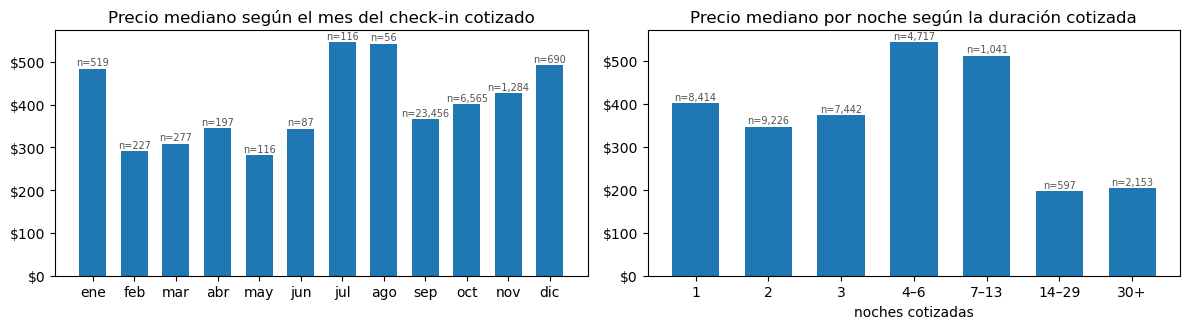

Cotizaciones con check-in en septiembre u octubre: 89%
Precio mediano por noche, estancia mínima < 30 noches: $385  |  >= 30 noches: $202


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
meses = df.groupby("quote_checkin_month")["price"].agg(["median", "size"])
nombres = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
axes[0].bar([nombres[m - 1] for m in meses.index], meses["median"], width=0.65)
for i, (v, n) in enumerate(zip(meses["median"], meses["size"])):
    axes[0].text(i, v + 8, f"n={n:,}", ha="center", fontsize=7, color="#52514e")
axes[0].yaxis.set_major_formatter(usd); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Precio mediano según el mes del check-in cotizado")

df["noches_bin"] = pd.cut(df["quote_nights"], [0, 1, 2, 3, 6, 13, 29, 400], labels=["1", "2", "3", "4–6", "7–13", "14–29", "30+"])
noches = df.groupby("noches_bin", observed=True)["price"].agg(["median", "size"])
axes[1].bar(noches.index.astype(str), noches["median"], width=0.65)
for i, (v, n) in enumerate(zip(noches["median"], noches["size"])):
    axes[1].text(i, v + 8, f"n={n:,}", ha="center", fontsize=7, color="#52514e")
axes[1].yaxis.set_major_formatter(usd); axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("noches cotizadas"); axes[1].set_title("Precio mediano por noche según la duración cotizada")
plt.tight_layout()
plt.show()
print(f"Cotizaciones con check-in en septiembre u octubre: {df['quote_checkin_month'].isin([9, 10]).mean():.0%}")
print(f"Precio mediano por noche, estancia mínima < 30 noches: ${df.loc[df['long_stay']==0,'price'].median():,.0f}  |  >= 30 noches: ${df.loc[df['long_stay']==1,'price'].median():,.0f}")

Anfitrion y reseñas

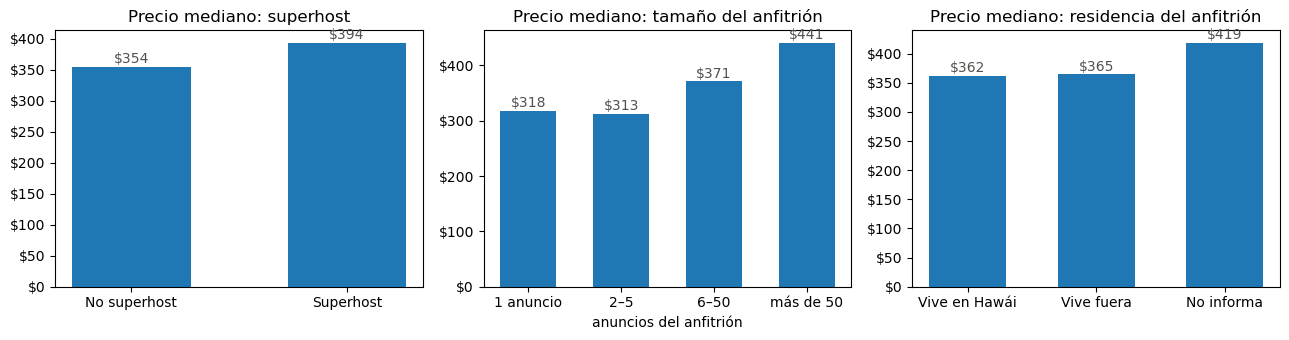

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
g = df.groupby("host_is_superhost")["price"].median()
axes[0].bar(["No superhost", "Superhost"], g.values, width=0.55)
for i, v in enumerate(g.values):
    axes[0].text(i, v + 6, f"${v:,.0f}", ha="center", color="#52514e")
axes[0].yaxis.set_major_formatter(usd); axes[0].grid(axis="x", visible=False); axes[0].set_title("Precio mediano: superhost")

g = df.groupby("host_size", observed=True)["price"].median()
axes[1].bar(g.index.astype(str), g.values, width=0.6)
for i, v in enumerate(g.values):
    axes[1].text(i, v + 6, f"${v:,.0f}", ha="center", color="#52514e")
axes[1].yaxis.set_major_formatter(usd); axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("anuncios del anfitrión"); axes[1].set_title("Precio mediano: tamaño del anfitrión")

g = df.groupby("host_location_group")["price"].median().reindex(["Hawaii", "Elsewhere", "Unknown"])
axes[2].bar(["Vive en Hawái", "Vive fuera", "No informa"], g.values, width=0.6)
for i, v in enumerate(g.values):
    axes[2].text(i, v + 6, f"${v:,.0f}", ha="center", color="#52514e")
axes[2].yaxis.set_major_formatter(usd); axes[2].grid(axis="x", visible=False); axes[2].set_title("Precio mediano: residencia del anfitrión")
plt.tight_layout()
plt.show()

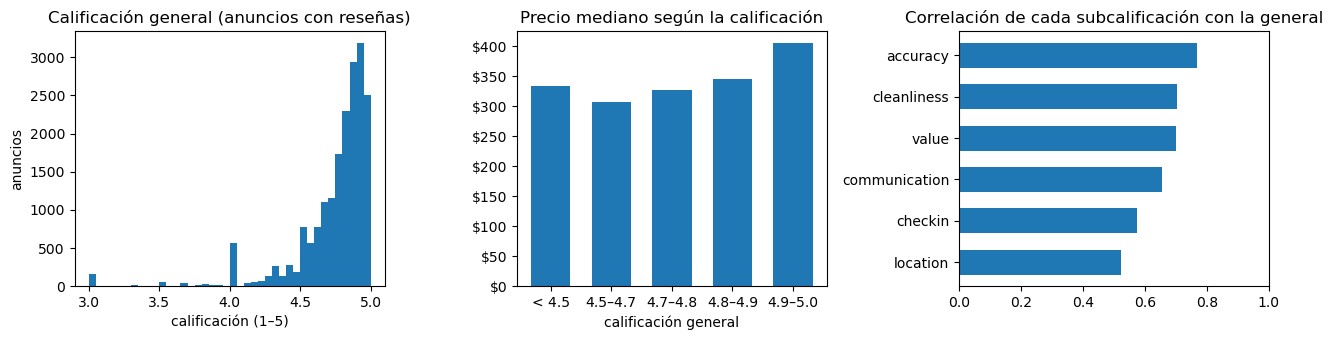

Anuncios con reseñas: 26,316 (78%)  |  Calificación mediana: 4.89  |  Con 4.8 o más: 68%  |  Con menos de 4.5: 8%
Correlación de Spearman precio–calificación: 0.20  |  precio–calificación de valor: 0.01


In [62]:
res = df[df["has_reviews"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(res["review_scores_rating"], bins=np.arange(3, 5.025, 0.05))
axes[0].set_title("Calificación general (anuncios con reseñas)"); axes[0].set_xlabel("calificación (1–5)"); axes[0].set_ylabel("anuncios")

g = res.groupby("rating_band", observed=True)["price"].median()
axes[1].bar(g.index.astype(str), g.values, width=0.65)
axes[1].yaxis.set_major_formatter(usd); axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("calificación general"); axes[1].set_title("Precio mediano según la calificación")

sub = ["review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication",
       "review_scores_location", "review_scores_value"]
corr_sub = res[sub].corrwith(res["review_scores_rating"], method="spearman").sort_values()
axes[2].barh(corr_sub.index.str.replace("review_scores_", ""), corr_sub.values, height=0.6)
axes[2].set_xlim(0, 1); axes[2].grid(axis="y", visible=False)
axes[2].set_title("Correlación de cada subcalificación con la general")
plt.tight_layout()
plt.show()
print(f"Anuncios con reseñas: {len(res):,} ({len(res)/len(df):.0%})  |  Calificación mediana: {res['review_scores_rating'].median():.2f}  |  "
      f"Con 4.8 o más: {(res['review_scores_rating'] >= 4.8).mean():.0%}  |  Con menos de 4.5: {(res['review_scores_rating'] < 4.5).mean():.0%}")
print(f"Correlación de Spearman precio–calificación: {res['price'].corr(res['review_scores_rating'], method='spearman'):.2f}  |  "
      f"precio–calificación de valor: {res['price'].corr(res['review_scores_value'], method='spearman'):.2f}")

tenemso que lus superanfitriones cobran una mediana 11% mayor (394 frente a 354 usd)

los operadores con 50 anuncios o mas cobran 441 USD mas que los anfitriones individuales 318 

las calificaciones tienen muy poca variacion la mediaan es 4.89

la calificacion tiene una relacion muy baja con el precio

Caso apto vs habitacion 

In [64]:
base = df[(df["am_wifi"] == 1) & (df["long_stay"] == 0)]
completo = base[(base["room_type"] == "Entire home/apt") & (base["bedrooms"] == 2) & (base["bathrooms"] == 1)
                & base["property_group"].isin(["Condo", "Apartment"])]
habitacion = base[(base["room_type"] == "Private room") & (base["bedrooms"] == 1) & (base["bathrooms"] <= 1)
                  & base["property_group"].isin(["Condo", "Apartment", "House"])]

def resumen(d):
    return d.groupby("island")["price"].agg(anuncios="size", p25=lambda s: s.quantile(.25), mediana="median", p75=lambda s: s.quantile(.75))

caso = pd.concat({"Apartamento completo (2 hab., 1 baño)": resumen(completo), "Habitación privada": resumen(habitacion)}, axis=1).round(0)
caso

Apartamento completo (2 hab., 1 baño)                        \
                                      anuncios    p25 mediana    p75   
island                                                                 
Hawaii                                     140  242.0   295.0  376.0   
Honolulu                                   215  293.0   405.0  494.0   
Kauai                                       68  327.0   390.0  500.0   
Maui                                       203  330.0   413.0  545.0   

         Habitación privada                        
                   anuncios    p25 mediana    p75  
island                                             
Hawaii                  187  115.0   143.0  177.0  
Honolulu                 65   93.0   170.0  254.0  
Kauai                    29  225.0   279.0  377.0  
Maui                     29  178.0   212.0  292.0

In [65]:
print(f"Total comparables — apartamento completo: {len(completo):,} (mediana ${completo['price'].median():,.0f})  |  "
      f"habitación privada: {len(habitacion):,} (mediana ${habitacion['price'].median():,.0f})")

Total comparables — apartamento completo: 626 (mediana $377)  |  habitación privada: 310 (mediana $160)


caso de como clasificar entre recomendado y no recomendado

primero que tengan almenos 5 reseñas pues su desviacion pasa de 0,81 con 1 a 0.29 de 5 a 9 


calificacion mayor a 4.8 que es lo minimo para ser super host

Valor >= a 4.7 , esto porque valor no es cuanto pagan sino si lo que pagaron esta acorde a lo que recibieron

almenos una reseña en el ultimo año (filtro de porbabilidad de que no este operativo)

retiramos del entrenamiento aquellos sin reseñas porque pueden ser muy nuevos y los queremos calificar netamente por sus caracteristicas los marcamos como sin evidencia

In [ ]:
con_resena = df["has_reviews"] == 1
activa = df["number_of_reviews_ltm"] >= 1
calidad = (df["review_scores_rating"] >= 4.8) & (df["review_scores_value"] >= 4.7)
df["evidencia"] = (df["number_of_reviews"] >= 5) & activa
df["recommended"] = np.where(df["evidencia"], calidad.astype(float), np.nan)
pasos = pd.Series({
    "Todos los anuncios": len(df),
    "Con al menos 1 reseña": int(con_resena.sum()),
    f"Con {5} o más reseñas": int((df["number_of_reviews"] >= 5).sum()),
    "… y al menos 1 en los últimos 12 meses (etiquetados)": int(df["evidencia"].sum()),
    "Recomendados": int((df["recommended"] == 1).sum()),
    "No recomendados": int((df["recommended"] == 0).sum()),
    "Sin evidencia suficiente (los clasifica el modelo)": int(df["recommended"].isna().sum()),
})
print(pd.DataFrame({"anuncios": pasos, "% del total": (pasos / len(df) * 100).round(1)}).to_string())

                                                      anuncios  % del total
Todos los anuncios                                       33590        100.0
Con al menos 1 reseña                                    26316         78.3
Con 5 o más reseñas                                      20212         60.2
… y al menos 1 en los últimos 12 meses (etiquetados)     18337         54.6
Recomendados                                             11095         33.0
No recomendados                                           7242         21.6
Sin evidencia suficiente (los clasifica el modelo)       15253         45.4


In [78]:
import re
import os
DATA_PATH = os.environ.get("CLEAN_PATH", "listings_clean.csv")
OUT_DIR = os.environ.get("OUT_DIR", ".")
PRED_NUM = ["latitude", "longitude", "price", "accommodates", "bedrooms", "beds", "bathrooms", "bath_shared", "minimum_nights",
            "maximum_nights", "long_stay", "availability_30", "availability_365", "host_has_profile_pic", "host_identity_verified",
            "host_years", "calculated_host_listings_count", "has_license", "n_amenities"] + [c for c in df.columns if c.startswith("am_")]
PRED_CAT = ["island", "neighbourhood", "room_type", "property_group", "host_location_group"]
X9 = pd.get_dummies(df[PRED_NUM + PRED_CAT], columns=PRED_CAT, dtype=int)
X9.insert(0, "log_price", np.log(df["price"]))
X9 = X9.drop(columns="price")
X9.columns = [re.sub(r"[^0-9a-zA-Z_]+", "_", c).strip("_").lower() for c in X9.columns]
X9.insert(0, "id", df["id"])
train9 = X9[df["evidencia"]].assign(recommended=df.loc[df["evidencia"], "recommended"].astype(int))
sin_ev9 = X9[~df["evidencia"]]
assert train9.isna().sum().sum() == 0 and sin_ev9.isna().sum().sum() == 0
train9.to_csv(os.path.join(OUT_DIR, "clasificacion_train.csv"), index=False)
sin_ev9.to_csv(os.path.join(OUT_DIR, "clasificacion_sin_evidencia.csv"), index=False)
print(f"clasificacion_train.csv: {train9.shape[0]:,} anuncios x {train9.shape[1] - 2} predictoras  |  recomendados: {train9['recommended'].mean():.1%}")
print(f"clasificacion_sin_evidencia.csv: {sin_ev9.shape[0]:,} anuncios")

clasificacion_train.csv: 18,337 anuncios x 83 predictoras  |  recomendados: 60.5%
clasificacion_sin_evidencia.csv: 15,253 anuncios


Como debemos predecir con informacion previa a las reseñas se excluyen las predictores review_scores, `umber_of_reviews, reviews_per_month, has_reviews, days_since_last_review, months_since_first_review -> debido a que definen a la poblacion etiquetada un airbnb nuevo no las tiene estimated_occupancy_l365d -> se calcuila a partir de las reseñas

por lo que sacamos esas variables pero le dejamos la etiqueta de recomendado. asi puede reconocer que patrones del alojamiento

Correlacion con el precio por noche (variable de interes)

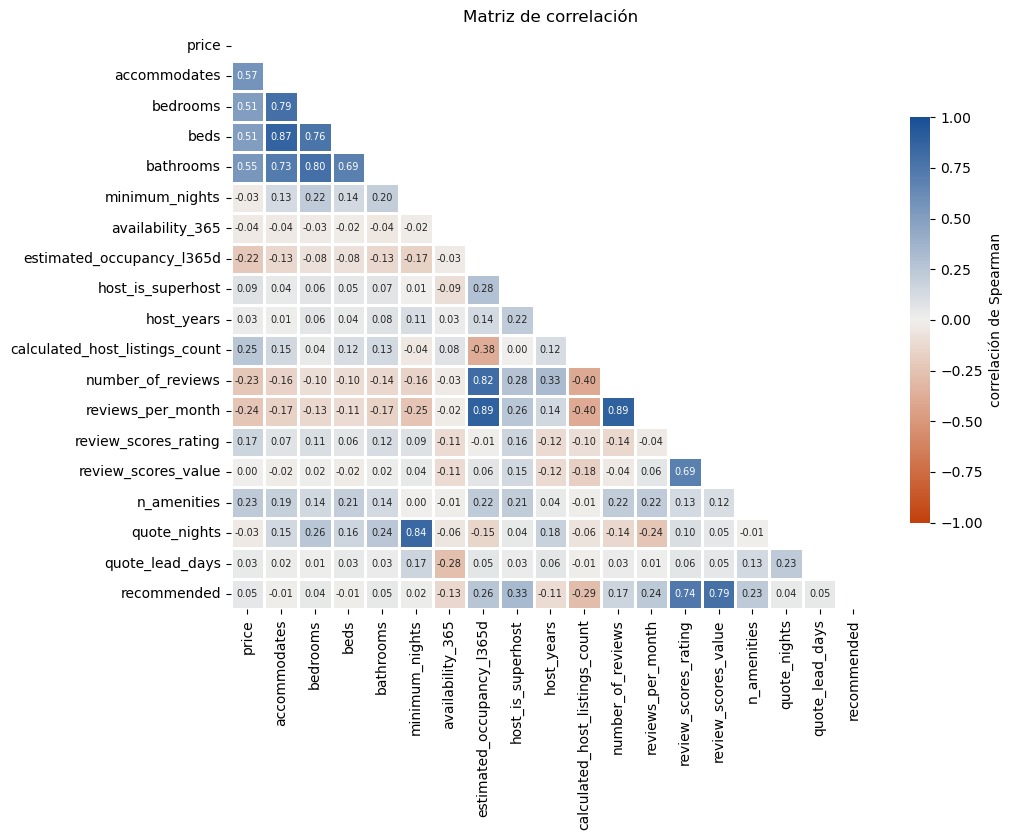

In [80]:
vars_corr = ["price", "accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights", "availability_365",
             "estimated_occupancy_l365d", "host_is_superhost", "host_years", "calculated_host_listings_count",
             "number_of_reviews", "reviews_per_month", "review_scores_rating", "review_scores_value", "n_amenities",
             "quote_nights", "quote_lead_days", "recommended"]
corr = df[vars_corr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap=LinearSegmentedColormap.from_list("div", ["#c2410c", "#f0efec", "#184f95"]), vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=1, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "correlación de Spearman"}, ax=ax)
ax.grid(False); ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

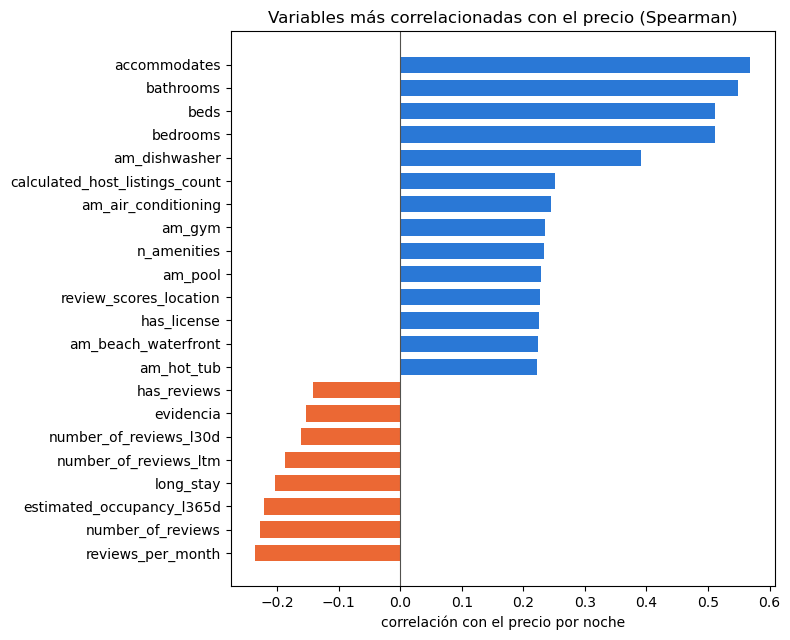

In [82]:
todas = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c not in
         ("id", "price", "log_price", "price_per_person", "latitude", "longitude", "recommended")]
cp = df[todas].corrwith(df["price"], method="spearman").sort_values()
sel = pd.concat([cp.head(8), cp.tail(14)])
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(sel.index, sel.values, color=["#2a78d6" if v > 0 else "#eb6834" for v in sel.values], height=0.7)
ax.axvline(0, color="#52514e", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_title("Variables más correlacionadas con el precio (Spearman)")
ax.set_xlabel("correlación con el precio por noche")
plt.tight_layout()
plt.show()